# Imager Validation: NOAA-20 CrIS

This notebook validates TAT-C's representation of a cross-track sounder against the [Cross-track Infrared Sounder (CrIS)](https://www.star.nesdis.noaa.gov/jpss/CrIS.php) aboard NOAA-20 (JPSS-1). CrIS is a Fourier-transform spectrometer (3.9 to 15.4 um) that scans perpendicular to the flight direction in 30 fields of regard (FORs) spaced about 3.33 deg apart, from -48.33 to +48.33 deg (a swath about 2,200 km wide), every 8 s. Each FOR holds a 3 x 3 array of circular fields of view (FOVs), 0.963 deg in diameter (about 14 km at nadir) on a pitch of about 1.1 deg (about 16 km) ([WMO OSCAR](https://space.oscar.wmo.int/instruments/view/cris)).

TAT-C does not model the scan mechanism. As described in the companion notebook, [Imager Validation: NOAA-20 ATMS](ValidateImagerATMS.ipynb), every pixel of a `PointedInstrument` view is observed at the same instant, and the along-track field of view stands in for the time the instrument takes to scan. CrIS is modeled as a rectangular view of 30 x 3 = 90 cross-track and 3 along-track pixels, three pixels for each FOR in each direction. The comparison asks five questions:

1. **Orbit.** Does TAT-C's propagation of the operational two-line element (TLE) set reproduce NOAA-20's position?
2. **Scan geometry.** Which scan angles, array layout, and scan plane orientation reproduce the actual scan?
3. **Geolocation.** How closely do TAT-C's pixel positions (`collect_ground_pixels`) match the reported FOV positions, and how much of the difference comes from scan timing and the rotation of the FOV array, which TAT-C does not model?
4. **Swath.** Does TAT-C's swath (`compute_ground_track`) match the area CrIS samples, for time steps from one scan to two minutes?
5. **Footprint size.** Does the satellite viewing geometry reproduce the reported zenith angles and ranges on which the footprint size depends, and how large are CrIS footprints and how do they grow toward the swath edge? Footprint size (horizontal resolution) is the figure of merit of the [monsoon OSSE example](../examples/RunOSSEMonsoon.ipynb), which uses the parameters fit here.

## Reference Data

NOAA distributes Joint Polar Satellite System (JPSS) data through the [NOAA Open Data Dissemination](https://www.noaa.gov/nodd) program. The NOAA-20 archive is public on AWS ([`noaa-nesdis-n20-pds`](https://registry.opendata.aws/noaa-jpss/)) and requires no account. Two products are used, as in the ATMS validation:

* **CrIS SDR geolocation** (`CrIS-SDR-GEO`, files `GCRSO_*`): one HDF5 file per 32 s granule of four 8 s scans. For each scan, it gives the start and middle times and the spacecraft's Earth-fixed position and velocity at the middle time. For each of the 30 FORs, it gives the time, and for each of its nine FOVs, the geodetic latitude, longitude, and height of the FOV center, the satellite zenith angle, and the slant range.
* **Two-line elements** (`TLE-AUX`): the element sets used by the JPSS ground system, one per day with an epoch at 00:00 UTC.

Two hours of one day (12:00 to 14:00 UTC on 2 October 2026; 225 granules, about 21 MB), more than the 101-minute orbit used in the swath test, are downloaded with `requests` and read with `h5py` (`pip install h5py`). Reduced arrays are cached in a local `data/jpss` directory, so later runs are fast.

In [1]:
import concurrent.futures
import io
import re
from datetime import datetime, timezone
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import requests

DATA_DIR = Path("data") / "jpss"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BUCKET = "https://noaa-nesdis-n20-pds.s3.amazonaws.com/"
DAY = datetime(2026, 10, 2, tzinfo=timezone.utc)
HOURS = (12, 14)  # UTC hour range of the geolocation granules used


def list_keys(prefix):
    """Keys of all objects in the bucket with a prefix."""
    keys, token = [], None
    while True:
        params = {"list-type": "2", "prefix": prefix}
        if token:
            params["continuation-token"] = token
        listing = requests.get(BUCKET, params=params, timeout=60).content.decode()
        keys += re.findall(r"<Key>(.*?)</Key>", listing)
        match = re.search(r"<NextContinuationToken>(.*?)</NextContinuationToken>", listing)
        if match is None:
            return keys
        token = match.group(1)


def fetch(key):
    """Download an object, retrying transient failures."""
    for attempt in range(5):
        try:
            response = requests.get(BUCKET + key, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == 4:
                raise


TLE_FILE = DATA_DIR / f"n20_tle_{DAY:%Y%m%d}.txt"
if not TLE_FILE.exists():
    # the element set with an epoch at the start of the day
    key = next(k for k in list_keys(f"TLE-AUX/{DAY:%Y/%m/%d}/") if f"Z_{DAY:%Y%m%d}000000Z_" in k)
    with h5py.File(io.BytesIO(fetch(key))) as f:
        TLE_FILE.write_text(bytes(f["All_Data/TLE-AUX_All/Dataset_Array_0"][:]).decode().strip() + "\n")
tle = TLE_FILE.read_text().splitlines()

CRIS_FILE = DATA_DIR / f"cris_gcrso_{DAY:%Y%m%d}_{HOURS[0]:02d}-{HOURS[1]:02d}h.npz"
CRIS_FIELDS = [
    "StartTime", "MidTime", "FORTime", "SCPosition", "SCVelocity", "Latitude", "Longitude", "Height",
    "SatelliteZenithAngle", "SatelliteRange", "QF1_CRISSDRGEO",
]
if not CRIS_FILE.exists():

    def read_granule(key):
        with h5py.File(io.BytesIO(fetch(key))) as f:
            return {field: f["All_Data/CrIS-SDR-GEO_All/" + field][:] for field in CRIS_FIELDS}

    keys = [
        k
        for k in list_keys(f"CrIS-SDR-GEO/{DAY:%Y/%m/%d}/")
        if HOURS[0] <= int(re.search(r"_t(\d{2})\d{5}_", k).group(1)) < HOURS[1]
    ]
    with concurrent.futures.ThreadPoolExecutor(16) as pool:
        granules = list(pool.map(read_granule, keys))
    np.savez_compressed(CRIS_FILE, **{field: np.concatenate([g[field] for g in granules]) for field in CRIS_FIELDS})

cris = dict(np.load(CRIS_FILE))
print(tle[0], tle[1], sep="\n")
pd.Series({"scans": len(cris["MidTime"]), "FORs per scan": cris["Latitude"].shape[1], "FOVs per FOR": cris["Latitude"].shape[2]})

1 43013U 17073A   26275.00000000  .00000083  00000-0  39562-4 0  2455
2 43013 098.7849 213.5412 0000651 045.7112 319.4843 14.19528658459636


scans            900
FORs per scan     30
FOVs per FOR       9
dtype: int64

## Setup

Times in JPSS products count microseconds since 1 January 1958 including leap seconds (IDPS Epoch Time, IET); subtracting the 37 leap seconds in effect gives UTC. Scans flagged by the quality flag or with missing (fill value) positions are excluded.

NOAA-20 is modeled with the operational TLE. The nominal CrIS scan has 30 FORs spaced `2 x 48.33 / 29` = 3.333 deg apart, and TAT-C's CrIS model has 90 pixels spaced a third of that (1.111 deg), so the cross-track field of view is 30 x 3.333 = 100 deg and the field of regard spans the outermost FOR centers, 96.66 deg. TAT-C numbers pixels starting from the right of the direction of motion and from the fore, and the layout test below determines how CrIS FOVs map to them. Helper functions convert between geodetic and Earth-fixed coordinates and decompose horizontal offsets into components along and to the right of a reference direction.

In [2]:
from datetime import timedelta

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.optimize import least_squares
from scipy.spatial import cKDTree
from skyfield.api import wgs84
from skyfield.framelib import itrs

from tatc.analysis import collect_ground_pixels, compute_ground_track
from tatc.constants import EARTH_MEAN_RADIUS, EARTH_ROTATION_RATE
from tatc.schemas import GeneralPerturbationsOrbit, Instrument, PointedInstrument, Satellite
from tatc.utils import VelocityFrame, field_of_regard_to_swath_width

IET_EPOCH = pd.Timestamp("1958-01-01", tz="UTC")
LEAP_SECONDS = 37
N_FOR, N_FOV = 30, 9  # fields of regard per scan, fields of view per field of regard (3 x 3)
EDGE = 48.33  # deg, nominal scan angle of the outermost field of regard
FOR_SPACING = 2 * EDGE / (N_FOR - 1)  # deg
FOV_SPACING = FOR_SPACING / 3  # deg, spacing of the 3 x 3 array within a field of regard
FOV_DIAMETER = 0.963  # deg, nominal instantaneous field of view (diameter)
SCAN_PERIOD = 8  # s


def iet_to_utc(iet):
    return IET_EPOCH + pd.to_timedelta(np.asarray(iet) - LEAP_SECONDS * 1_000_000, unit="us")


good = (cris["QF1_CRISSDRGEO"] == 0) & np.all(np.abs(cris["Latitude"]) <= 90, axis=(1, 2))
t_mid = iet_to_utc(cris["MidTime"][good])
t_for = iet_to_utc(cris["FORTime"][good].ravel()).to_numpy().reshape(-1, N_FOR)
dt_for = (cris["FORTime"][good] - cris["MidTime"][good][:, np.newaxis]) / 1e6  # s from the middle time
sc_pos, sc_vel = cris["SCPosition"][good].astype(float), cris["SCVelocity"][good].astype(float)
fov_lat, fov_lon = cris["Latitude"][good].astype(float), cris["Longitude"][good].astype(float)
fov_height = cris["Height"][good].astype(float) if "Height" in cris else np.zeros_like(fov_lat)
fov_zenith = cris["SatelliteZenithAngle"][good].astype(float)
fov_range = cris["SatelliteRange"][good].astype(float)

noaa20 = Satellite(name="NOAA-20", orbit=GeneralPerturbationsOrbit.from_tle(tle))
orbit = noaa20.orbit.to_gp_orbit()

TO_ECEF = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)
TO_GEODETIC = Transformer.from_crs("EPSG:4978", "EPSG:4979", always_xy=True)


def ecef(lon, lat, height=0.0):
    """Earth-fixed position (m) of geodetic coordinates, stacked on the last axis."""
    return np.stack(TO_ECEF.transform(lon, lat, np.broadcast_to(height, np.shape(lon))), axis=-1)


def up(lon, lat):
    """Geodetic up unit vector, stacked on the last axis."""
    lon, lat = np.radians(lon), np.radians(lat)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)


def normalize(x):
    return x / np.linalg.norm(x, axis=-1, keepdims=True)


def along_right(lon, lat, offset, direction):
    """Components (km) of Earth-fixed offsets along and to the right of the horizontal projection of a direction at a location."""
    u = up(lon, lat)
    along = normalize(direction - np.sum(direction * u, axis=-1, keepdims=True) * u)
    right = np.cross(along, u)
    return np.sum(offset * along, axis=-1) / 1e3, np.sum(offset * right, axis=-1) / 1e3


def inertial_velocity(position, velocity):
    """Inertial velocity expressed in Earth-fixed coordinates."""
    return velocity + EARTH_ROTATION_RATE * np.stack(
        [-position[..., 1], position[..., 0], np.zeros(position.shape[:-1])], axis=-1
    )


def summarize(x):
    """Summary statistics of a residual sample."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return pd.Series(
        {
            "n": x.size,
            "median": np.median(x),
            "p95 |x|": np.percentile(np.abs(x), 95),
            "max |x|": np.abs(x).max(),
        }
    )


def binned(x, y, edges, q=(5, 50, 95)):
    """Percentiles of y in bins of x."""
    i = np.digitize(x, edges) - 1
    return np.array([np.percentile(y[i == k], q) if np.any(i == k) else [np.nan] * len(q) for k in range(len(edges) - 1)])


BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)
pd.Series(
    {
        "scans used": int(good.sum()),
        "scans excluded": int((~good).sum()),
        "first scan (UTC)": t_mid[0],
        "last scan (UTC)": t_mid[-1],
        "FOV height range (m)": f"{fov_height.min():.0f} to {fov_height.max():.0f}",
    }
)

scans used                                           900
scans excluded                                         0
first scan (UTC)        2026-10-02 12:00:05.883963+00:00
last scan (UTC)         2026-10-02 13:59:57.883964+00:00
FOV height range (m)                           -66 to 67
dtype: object

## Test 1: Orbit

In [3]:
i1 = np.arange(0, len(t_mid), 5)
p1, v1 = orbit.get_orbit_track(list(t_mid[i1])).frame_xyz_and_velocity(itrs)
offset1 = np.array(p1.m).T - sc_pos[i1]
radial1 = normalize(sc_pos[i1])
along1 = normalize(sc_vel[i1] - np.sum(sc_vel[i1] * radial1, axis=-1, keepdims=True) * radial1)
test1 = pd.DataFrame(
    {
        "along-track (km)": summarize(np.sum(offset1 * along1, axis=-1) / 1e3),
        "cross-track, right (km)": summarize(np.sum(offset1 * np.cross(along1, radial1), axis=-1) / 1e3),
        "radial (km)": summarize(np.sum(offset1 * radial1, axis=-1) / 1e3),
        "velocity (m/s)": summarize(np.linalg.norm(np.array(v1.m_per_s).T - sc_vel[i1], axis=-1)),
    }
).T
test1.round(3)

,n,median,p95 |x|,max |x|
along-track (km),180.0,0.499,0.688,0.693
"cross-track, right (km)",180.0,0.023,0.282,0.287
radial (km),180.0,0.042,0.132,0.133
velocity (m/s),180.0,0.590,0.690,0.740


The TLE reproduces NOAA-20's position to about 0.7 km along track (95th percentile) over the two hours, and much better radially and cross-track, which is small compared with a CrIS footprint (about 14 km at nadir).

## Test 2: Scan Geometry

This test uses only the reference data: the reported spacecraft position and velocity and the FOV positions.

CrIS samples each FOR for 0.2 s, so the FORs of a scan span about 5.8 s, starting at the scan's start time. The line of sight of each FOV is the vector from the spacecraft position at the FOR's time (extrapolated linearly from the reported position and velocity) to the FOV center. The lines of sight to the centers of the FORs lie in a plane (the scan plane) to within about 0.03 deg. The cross-track (scan) angle of a line of sight is its angle from nadir within this plane, positive to the left of the direction of motion (TAT-C's positive roll direction), and its along-track angle is the angle out of the plane, positive forward.

### Scan Angles

The scan angle of each FOR is the mean over its nine FOVs. TAT-C rotates a rolled view rigidly, so a pixel's angle from nadir is the sum of the roll angle and the pixel's angular offset from the view center; the measured angles are fit with this model to find the effective spacing and roll angle.

In [4]:
# spacecraft position at each field of regard's time (extrapolated linearly from the middle time)
sc_for = sc_pos[:, np.newaxis] + sc_vel[:, np.newaxis] * dt_for[..., np.newaxis]  # (scan, FOR, xyz)
fov_xyz = ecef(fov_lon, fov_lat, fov_height)  # (scan, FOR, FOV, xyz)
sc_lon, sc_lat, _ = TO_GEODETIC.transform(sc_for[..., 0], sc_for[..., 1], sc_for[..., 2])
nadir = -up(sc_lon, sc_lat)  # (scan, FOR, xyz)
los = normalize(fov_xyz - sc_for[:, :, np.newaxis])  # (scan, FOR, FOV, xyz)

# the scan plane of each scan: normal to the lines of sight to the centers of its fields of regard
los_for = normalize(los.mean(axis=2))
normal = np.array([np.linalg.svd(los_for[k])[2][-1] for k in range(len(los_for))])
normal *= np.sign(np.sum(normal * sc_vel, axis=-1))[:, np.newaxis]  # facing forward
n_ = normal[:, np.newaxis]
# cross-track (scan) angle in the scan plane, positive to the left, and along-track angle out of it, positive forward
nadir_plane = normalize(nadir - np.sum(nadir * n_, axis=-1, keepdims=True) * n_)
left_plane = np.cross(n_, nadir_plane)
los_plane = los - np.sum(los * n_[:, :, np.newaxis], axis=-1, keepdims=True) * n_[:, :, np.newaxis]
cross_angle = np.degrees(
    np.arctan2(np.sum(los_plane * left_plane[:, :, np.newaxis], axis=-1), np.sum(los_plane * nadir_plane[:, :, np.newaxis], axis=-1))
)
along_angle = np.degrees(np.arcsin(np.einsum("kjic,kc->kji", los, normal)))
for_angle = cross_angle.mean(axis=2)  # scan angle of the center of each field of regard
measured = np.median(for_angle, axis=0)
orientation = np.sign(measured[0] - measured[-1])  # +1 if field of regard 0 is on the left
nominal = orientation * ((N_FOR - 1) / 2 - np.arange(N_FOR)) * FOR_SPACING


def model(params, index=np.arange(N_FOR)):
    spacing, roll = params
    return roll + orientation * spacing * ((N_FOR - 1) / 2 - index)


fit = least_squares(lambda params: model(params) - measured, [FOR_SPACING, 0]).x
fitted_spacing, fitted_roll = fit
pd.Series(
    {
        "field of regard 0 side": "left" if orientation > 0 else "right",
        "sample interval, field of regard (ms)": np.median(np.diff(dt_for, axis=1)) * 1e3,
        "nominal spacing (deg)": FOR_SPACING,
        "fitted spacing (deg)": fitted_spacing,
        "fitted roll (deg)": fitted_roll,
        "fit residual, max |x| (deg)": np.abs(model(fit) - measured).max(),
        "scan-to-scan std. dev., median (deg)": np.median(np.std(for_angle, axis=0)),
        "left edge, measured (deg)": measured.max(),
        "right edge, measured (deg)": measured.min(),
        "field of regard, measured (deg)": measured.max() - measured.min(),
    }
).round(4)

field of regard 0 side                        left
sample interval, field of regard (ms)        200.0
nominal spacing (deg)                     3.333103
fitted spacing (deg)                       3.33399
fitted roll (deg)                        -0.092556
fit residual, max |x| (deg)               0.009403
scan-to-scan std. dev., median (deg)      0.000875
left edge, measured (deg)                48.254462
right edge, measured (deg)              -48.431246
field of regard, measured (deg)          96.685708
dtype: object

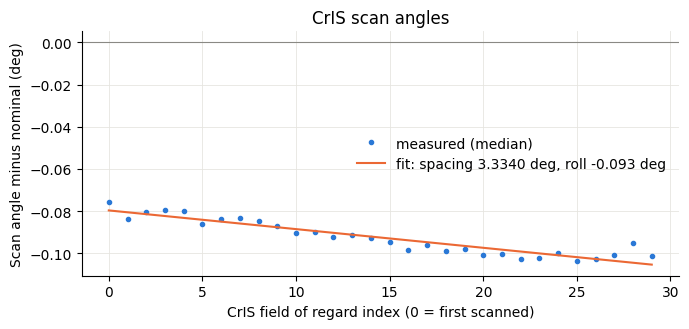

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(N_FOR), measured - nominal, color=BLUE, marker="o", ms=3, lw=0, label="measured (median)")
ax.plot(np.arange(N_FOR), model(fit) - nominal, color=ORANGE, label=f"fit: spacing {fitted_spacing:.4f} deg, roll {fitted_roll:+.3f} deg")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set(xlabel="CrIS field of regard index (0 = first scanned)", ylabel="Scan angle minus nominal (deg)", title="CrIS scan angles")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The measured scan angles are stable from scan to scan (a standard deviation of about 0.001 deg) and fit the rigid-rotation model to within 0.01 deg with a spacing of 3.334 deg, matching the nominal 3.333 deg, and a roll of 0.09 deg to the right. FOR 0 is scanned first, on the left. The measured field of regard (96.69 deg) is within 0.03 deg of the nominal 96.66 deg.

### Field of View Layout

The offsets of each FOV from the center of its FOR, in the scan plane (cross-track, positive left) and out of it (along-track, positive forward), are taken from the two FORs nearest nadir (whose small rotations cancel). They show a square 3 x 3 array on a pitch of 1.092 deg, slightly smaller than the nominal 1.1 deg, with FOV 5 at the center. The table also gives each FOV's TAT-C pixel indices within its FOR (cross-track 0 on the right to 2 on the left, along-track 0 at the fore to 2 at the aft), used in the geolocation test.

In [6]:
# offsets of each view from the center of its field of regard (deg): cross-track (positive left) and along-track (positive forward)
offset_cross = cross_angle - for_angle[..., np.newaxis]
offset_along = along_angle - along_angle.mean(axis=2, keepdims=True)
fov_offsets = np.stack([np.median(offset_cross, axis=0), np.median(offset_along, axis=0)], axis=-1)  # (FOR, FOV, 2)
central = [N_FOR // 2 - 1, N_FOR // 2]  # fields of regard nearest nadir (symmetric, so their rotations cancel)
reference = fov_offsets[central].mean(axis=0)  # (FOV, 2)
layout = pd.DataFrame(
    {"cross-track offset (deg)": reference[:, 0], "along-track offset (deg)": reference[:, 1]},
    index=pd.RangeIndex(1, N_FOV + 1, name="FOV"),
)
fov_pitch = np.sort(np.hypot(*reference.T))[1:5].mean()  # distance to the four nearest neighbors of the central view
# TAT-C pixel indices within a field of regard: cross-track 0 (right) to 2 (left), along-track 0 (fore) to 2 (aft)
pixel_cross = np.round(reference[:, 0] / fov_pitch).astype(int) + 1
pixel_along = 1 - np.round(reference[:, 1] / fov_pitch).astype(int)
assert len(set(zip(pixel_cross, pixel_along))) == N_FOV
center = int(np.flatnonzero((pixel_cross == 1) & (pixel_along == 1))[0])  # the central view of the array
layout["TAT-C cross-track pixel"] = pixel_cross
layout["TAT-C along-track pixel"] = pixel_along
print(f"FOV pitch {fov_pitch:.4f} deg (nominal {FOV_SPACING:.4f}); central view: FOV {center + 1}")
layout.round(3)

FOV pitch 1.0918 deg (nominal 1.1110); central view: FOV 5


,cross-track offset (deg),along-track offset (deg),TAT-C cross-track pixel,TAT-C along-track pixel
FOV,,,,
1,1.090,-1.096,2,2
2,-0.003,-1.095,1,2
3,-1.098,-1.091,0,2
4,1.092,-0.003,2,1
5,0.000,0.000,1,1
6,-1.093,0.004,0,1
7,1.100,1.094,2,0
8,0.003,1.088,1,0
9,-1.092,1.099,0,0


The array of views turns as the scan mirror sweeps. The rotation of each field of regard's array from its layout at nadir (a rigid rotation fit to the nine views) is compared with its scan angle.

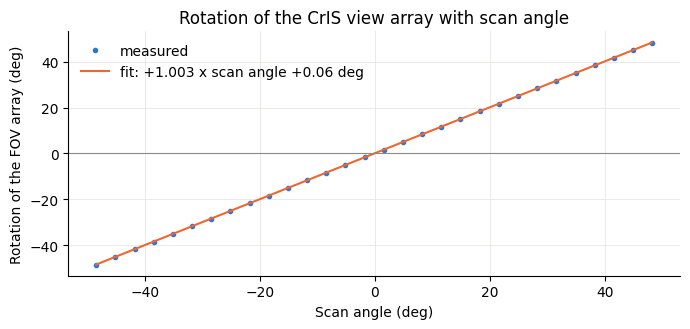

rotation per degree of scan angle     1.003
rotation at nadir (deg)               0.065
fit residual, max |x| (deg)           0.052
rotation at the left edge (deg)      48.405
rotation at the right edge (deg)    -48.547
dtype: float64

In [7]:
# angle (deg) of the rotation of the array (counterclockwise in cross-track, along-track axes) that best maps the nadir layout onto each field of regard
p = fov_offsets  # (FOR, FOV, 2)
rotation = np.degrees(
    np.arctan2(
        np.sum(reference[:, 0] * p[..., 1] - reference[:, 1] * p[..., 0], axis=1),
        np.sum(reference[:, 0] * p[..., 0] + reference[:, 1] * p[..., 1], axis=1),
    )
)
rotation_fit = np.polyfit(measured, rotation, 1)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(measured, rotation, color=BLUE, marker="o", ms=3, lw=0, label="measured")
ax.plot(measured, np.polyval(rotation_fit, measured), color=ORANGE, label=f"fit: {rotation_fit[0]:+.3f} x scan angle {rotation_fit[1]:+.2f} deg")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set(xlabel="Scan angle (deg)", ylabel="Rotation of the FOV array (deg)", title="Rotation of the CrIS view array with scan angle")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
pd.Series(
    {
        "rotation per degree of scan angle": rotation_fit[0],
        "rotation at nadir (deg)": rotation_fit[1],
        "fit residual, max |x| (deg)": np.abs(np.polyval(rotation_fit, measured) - rotation).max(),
        "rotation at the left edge (deg)": rotation[measured.argmax()],
        "rotation at the right edge (deg)": rotation[measured.argmin()],
    }
).round(3)

The array rotates with the scan angle, one degree per degree (as for a fixed focal plane behind a scan mirror), reaching about 48 deg at the swath edges. TAT-C's pixel array is a rigid, unrotated rectangle in every FOR, so it cannot represent this rotation; the effect is to displace the FOVs in a FOR (by up to about 60 km at the swath edge, as Test 3 shows), but not the center of the array.

### Scan Plane Orientation

As in the ATMS validation, the scan plane's normal is compared with the horizontal direction of the Earth-fixed and inertial velocity (with yaw angles positive counterclockwise viewed from above). The tilt of the plane forward of nadir is also computed, from the angle between the plane normal and the nadir at each FOR.

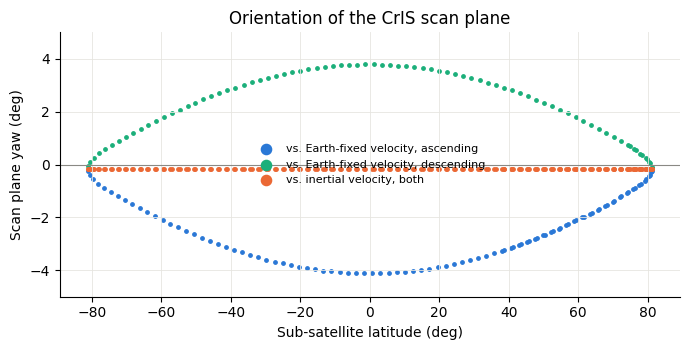

,n,median,p95 |x|,max |x|
yaw vs. Earth-fixed velocity (deg),180.0,-0.585,4.046,4.117
yaw vs. inertial velocity (deg),180.0,-0.165,0.166,0.166
line of sight out of plane (deg),5400.0,0.007,0.017,0.034
scan plane tilt forward (deg),180.0,0.223,0.228,0.229


In [8]:
i2 = np.arange(0, len(t_mid), 5)
sub_lon, sub_lat, _ = TO_GEODETIC.transform(sc_pos[i2, 0], sc_pos[i2, 1], sc_pos[i2, 2])
u2 = up(sub_lon, sub_lat)


def yaw(direction, reference):
    """Signed angle (deg) from the horizontal projection of a reference direction to that of a direction."""
    a = normalize(reference - np.sum(reference * u2, axis=-1, keepdims=True) * u2)
    b = normalize(direction - np.sum(direction * u2, axis=-1, keepdims=True) * u2)
    return np.degrees(np.arctan2(np.sum(np.cross(a, b) * u2, axis=-1), np.sum(a * b, axis=-1)))


normal2 = normal[i2]
yaw_earth_fixed = yaw(normal2, sc_vel[i2])
yaw_inertial = yaw(normal2, inertial_velocity(sc_pos[i2], sc_vel[i2]))
ascending = sc_vel[i2, 2] > 0
out_of_plane = np.degrees(np.abs(np.arcsin(np.einsum("kjc,kc->kj", los_for[i2], normal2))))
# tilt of the scan plane forward of nadir (positive forward), from the angle between the plane normal and the nadir at each field of regard
tilt = -np.degrees(np.arcsin(np.sum(nadir * normal[:, np.newaxis], axis=-1)))  # (scan, FOR)
scan_plane_tilt = float(np.median(tilt))

fig, ax = plt.subplots(figsize=(7, 3.6))
for mask, color, label in [(ascending, BLUE, "ascending"), (~ascending, AQUA, "descending")]:
    ax.scatter(sub_lat[mask], yaw_earth_fixed[mask], s=6, color=color, label=f"vs. Earth-fixed velocity, {label}")
ax.scatter(sub_lat, yaw_inertial, s=6, color=ORANGE, label="vs. inertial velocity, both")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set(xlabel="Sub-satellite latitude (deg)", ylabel="Scan plane yaw (deg)", title="Orientation of the CrIS scan plane", ylim=(-5, 5))
ax.legend(frameon=False, fontsize=8, markerscale=3, loc="center")
fig.tight_layout()
plt.show()
pd.DataFrame(
    {
        "yaw vs. Earth-fixed velocity (deg)": summarize(yaw_earth_fixed),
        "yaw vs. inertial velocity (deg)": summarize(yaw_inertial),
        "line of sight out of plane (deg)": summarize(out_of_plane),
        "scan plane tilt forward (deg)": summarize(np.median(tilt[i2], axis=1)),
    }
).T.round(3)

Like ATMS, the scan plane faces the inertial velocity at all latitudes, to within a constant 0.17 deg, whereas the Earth-fixed velocity is rotated by up to about 4 deg, with opposite signs on ascending and descending passes. A `PointedInstrument` with `velocity_frame=VelocityFrame.INERTIAL` reproduces this orientation. The scan plane is also tilted 0.22 deg forward of nadir on both ascending and descending passes (about 3 km on the ground), which `PointedInstrument.pitch_angle` can reproduce.

## Test 3: Geolocation

TAT-C pixel positions from `collect_ground_pixels`, at the middle time of every twentieth scan, are compared with the reported FOV positions. Five configurations isolate the contributions of the along-track reference direction, the scan angles, the scan plane tilt, and scan timing:

* **Nominal, Earth-fixed:** 3.333 deg FOR spacing with TAT-C's default velocity frame.
* **Nominal, inertial:** the same with `velocity_frame=VelocityFrame.INERTIAL`.
* **Fitted, inertial:** the FOR spacing, roll angle, and FOV pitch fitted in Test 2.
* **Fitted, inertial, tilted:** the same with the scan plane tilt as `pitch_angle`.
* **Fitted, inertial, tilted, sample times:** the same, but with each FOR projected at its own sample time rather than all at the scan's middle time. TAT-C does not do this; it is computed here (with `PointedInstrument.compute_projected_pixel_position`) to quantify the effect of scan timing.

Residuals (TAT-C minus CrIS) are decomposed along and to the right of the ground track (the horizontal direction of the reported Earth-fixed velocity). The first table gives the residuals of the central FOV of each FOR, the center of its array; the second, those of all nine FOVs.

In [9]:
N_PIX = N_FOR * 3
i3 = np.arange(0, len(t_mid), 20)
times3 = list(t_mid[i3])
# TAT-C cross-track pixel index (0 on the right) of each field of regard and view, and along-track pixel index of each view
for_position = (N_FOR - 1 - np.arange(N_FOR)) if orientation > 0 else np.arange(N_FOR)
cross_index = 3 * for_position[:, np.newaxis] + pixel_cross[np.newaxis, :]  # (FOR, FOV)
along_index = np.broadcast_to(pixel_along, cross_index.shape)

cris_pixels = PointedInstrument(
    name="CrIS",
    field_of_regard=N_FOR * FOR_SPACING,
    cross_track_field_of_view=N_FOR * FOR_SPACING,
    along_track_field_of_view=3 * FOV_SPACING,
    is_rectangular=True,
    cross_track_pixels=N_PIX,
    along_track_pixels=3,
)
fitted = {
    "velocity_frame": VelocityFrame.INERTIAL,
    "cross_track_field_of_view": N_FOR * fitted_spacing,
    "field_of_regard": N_FOR * fitted_spacing,
    "along_track_field_of_view": 3 * fov_pitch,
    "roll_angle": fitted_roll,
}
configs = {
    "nominal, Earth-fixed": cris_pixels,
    "nominal, inertial": cris_pixels.model_copy(update={"velocity_frame": VelocityFrame.INERTIAL}),
    "fitted, inertial": cris_pixels.model_copy(update=fitted),
    "fitted, inertial, tilted": cris_pixels.model_copy(update={**fitted, "pitch_angle": scan_plane_tilt}),
}
measured_lon = np.zeros((len(i3), N_PIX, 3))
measured_lat = np.zeros((len(i3), N_PIX, 3))
measured_lon[:, cross_index, along_index] = fov_lon[i3]
measured_lat[:, cross_index, along_index] = fov_lat[i3]

pixels = {}
for name, instrument in configs.items():
    track = collect_ground_pixels(noaa20.model_copy(update={"instruments": [instrument]}), times3)
    pixels[name] = (
        track.geometry.x.to_numpy().reshape(len(i3), N_PIX, 3),
        track.geometry.y.to_numpy().reshape(len(i3), N_PIX, 3),
    )
# each field of regard at its own sample time, which TAT-C does not model
sample_time_instrument = configs["fitted, inertial, tilted"]
lon3, lat3 = np.zeros((len(i3), N_PIX, 3)), np.zeros((len(i3), N_PIX, 3))
for j in range(N_FOR):
    track3 = orbit.get_orbit_track([t + timedelta(seconds=dt_for[k, j]) for k, t in zip(i3, times3)])
    for m in range(N_FOV):
        position = sample_time_instrument.compute_projected_pixel_position(track3, cross_index[j, m], along_index[j, m])
        lon3[:, cross_index[j, m], along_index[j, m]] = position.longitude.degrees
        lat3[:, cross_index[j, m], along_index[j, m]] = position.latitude.degrees
pixels["fitted, inertial, tilted, sample times"] = (lon3, lat3)

residuals3 = {
    name: along_right(
        measured_lon, measured_lat,
        ecef(lon, lat) - ecef(measured_lon, measured_lat),
        sc_vel[i3, np.newaxis, np.newaxis],
    )
    for name, (lon, lat) in pixels.items()
}


def per_for(values):
    """Values regrouped by field of regard and view: (scan, FOR, FOV)."""
    return values[:, cross_index, along_index]


def residual_table(select):
    return pd.DataFrame(
        {
            (name, component): summarize(select(values)).loc[["median", "p95 |x|", "max |x|"]]
            for name, (along, right) in residuals3.items()
            for component, values in [("along", along), ("right", right), ("horizontal", np.hypot(along, right))]
        }
    ).T.round(2)


display(residual_table(lambda values: per_for(values)[:, :, center]))
display(residual_table(lambda values: values))

median  p95 |x|  max |x|
nominal, Earth-fixed                   along        -2.83    59.21    93.66
                                       right        -1.73     4.25     6.02
                                       horizontal   12.42    59.33    93.69
nominal, inertial                      along        -2.88    21.22    22.95
                                       right        -1.77     3.61     4.90
                                       horizontal   10.13    21.51    23.45
fitted, inertial                       along        -2.92    21.23    22.86
                                       right        -0.04     0.26     0.49
                                       horizontal    9.96    21.23    22.86
fitted, inertial, tilted               along         0.40    19.04    19.59
                                       right         0.01     0.35     0.70
                                       horizontal   10.00    19.04    19.59
fitted, inertial, tilted, sample times along         0.45     0.67     0.72
                                       right         0.01     0.33     0.65
                                       horizontal    0.48     0.70     0.74

median  p95 |x|  max |x|
nominal, Earth-fixed                   along        -2.55    62.23   125.26
                                       right        -1.62    32.60    64.26
                                       horizontal   16.13    67.36   127.46
nominal, inertial                      along        -2.96    32.09    51.10
                                       right        -1.65    32.76    61.72
                                       horizontal   11.55    43.99    64.66
fitted, inertial                       along        -2.96    32.13    50.47
                                       right        -0.04    32.62    58.69
                                       horizontal   11.44    42.14    69.31
fitted, inertial, tilted               along         0.36    31.93    46.80
                                       right        -0.01    32.91    58.85
                                       horizontal   11.31    42.89    67.59
fitted, inertial, tilted, sample times along         0.49    18.86    27.68
                                       right        -0.00    32.92    58.87
                                       horizontal    8.37    34.71    60.38

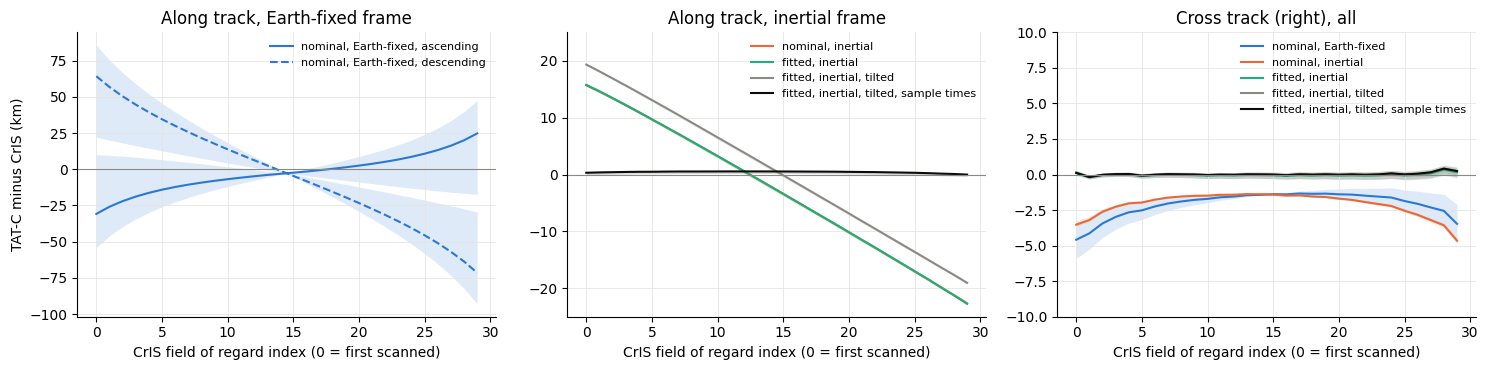

In [10]:
ascending3 = sc_vel[i3, 2] > 0
colors3 = dict(zip(residuals3, [BLUE, ORANGE, AQUA, GRAY, INK]))


def band(ax, values, color, label, ls="-"):
    """Percentiles (5, 50, 95) of residuals by field of regard, for values of shape (scan, FOR) or (scan, FOR, FOV)."""
    q = np.percentile(values.reshape(len(values), N_FOR, -1).transpose(1, 0, 2).reshape(N_FOR, -1), [5, 50, 95], axis=1)
    ax.fill_between(np.arange(N_FOR), q[0], q[2], color=color, alpha=0.15, lw=0)
    ax.plot(np.arange(N_FOR), q[1], color=color, ls=ls, label=label)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
along, right = residuals3["nominal, Earth-fixed"]
band(axes[0], per_for(along)[ascending3][:, :, center], BLUE, "nominal, Earth-fixed, ascending")
band(axes[0], per_for(along)[~ascending3][:, :, center], BLUE, "nominal, Earth-fixed, descending", ls="--")
for name, (along, right) in residuals3.items():
    if name != "nominal, Earth-fixed":
        band(axes[1], per_for(along)[:, :, center], colors3[name], name)
    band(axes[2], per_for(right)[:, :, center], colors3[name], name)
axes[0].set(ylabel="TAT-C minus CrIS (km)", title="Along track, Earth-fixed frame")
axes[1].set(title="Along track, inertial frame", ylim=(-25, 25))
axes[2].set(title="Cross track (right), all", ylim=(-10, 10))
for ax in axes:
    ax.set_xlabel("CrIS field of regard index (0 = first scanned)")
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Lines show medians and bands the 5th to 95th percentiles of the residuals of the central FOVs.

* **Along-track reference direction.** With TAT-C's default Earth-fixed velocity frame, the along-track residual of the central FOVs grows across the scan to about 60 km (95th percentile) with opposite signs on ascending and descending passes. The inertial velocity frame removes this error.
* **Scan timing.** With all pixels at the scan's middle time, the remaining along-track residual is a tilt across the scan of about 19 km at each edge: CrIS samples its first FOR 2.9 s before the middle time and its last 2.9 s after, while NOAA-20's ground track advances about 6.6 km/s. Projecting each FOR at its sample time removes the tilt. This is the integration time that TAT-C's single-instant view does not resolve, and it is much larger than for ATMS because a CrIS scan takes 5.8 s instead of 1.7 s.
* **Scan angles and tilt.** With the nominal spacing, the cross-track residual grows to about 4 km (95th percentile) at the edges; the fitted spacing and roll angle reduce it to 0.3 km. The fitted scan plane tilt removes a constant along-track bias of about 2.9 km.

With all three accounted for, TAT-C reproduces the centers of the CrIS FOR arrays to 0.5 km (median) and 0.7 km (95th percentile) everywhere in the swath, comparable to the orbit error of Test 1. The residuals of all FOVs are larger (95th percentile of about 35 km) only because TAT-C does not rotate the FOV array: its FOVs are displaced from the true ones, by up to about 60 km at the swath edges, which does not affect the extent of the swath or the footprint size.

## Test 4: Swath

### Swath Width

For a nadir `Instrument`, TAT-C converts the field of regard to a swath width with `field_of_regard_to_swath_width`, assuming a spherical Earth with the mean radius and the satellite's geodetic altitude. The observed swath width is the distance along the surface from the first to the last FOR center, through the intermediate FOR centers.

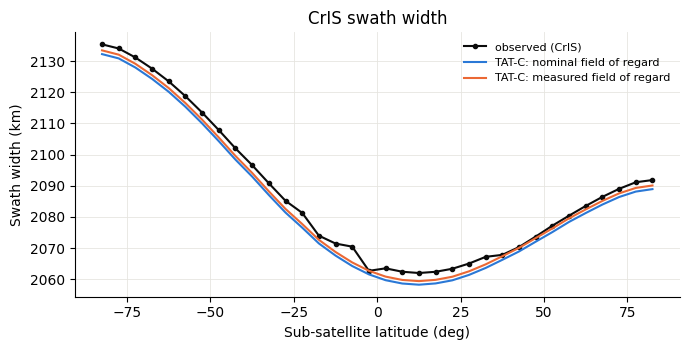

,n,median,p95 |x|,max |x|
nominal field of regard,450.0,-2.7,6.7,6.8
measured field of regard,450.0,-1.5,5.5,5.6


In [11]:
for_xyz = fov_xyz.mean(axis=2)
for_unit = normalize(for_xyz)
i4 = np.arange(0, len(t_mid), 2)
observed_width = np.sum(np.linalg.norm(np.diff(for_xyz[i4], axis=1), axis=-1), axis=1) / 1e3
sub4 = wgs84.geographic_position_of(orbit.get_orbit_track(list(t_mid[i4])))
swath_width = np.vectorize(field_of_regard_to_swath_width)
widths = {
    "nominal field of regard": swath_width(sub4.elevation.m, 2 * EDGE) / 1e3,
    "measured field of regard": swath_width(sub4.elevation.m, measured.max() - measured.min()) / 1e3,
}
edges4 = np.arange(-90, 91, 5)
centers4 = (edges4[:-1] + edges4[1:]) / 2
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(centers4, binned(sub4.latitude.degrees, observed_width, edges4)[:, 1], color=INK, marker="o", ms=3, label="observed (CrIS)")
for (name, width), color in zip(widths.items(), [BLUE, ORANGE]):
    ax.plot(centers4, binned(sub4.latitude.degrees, width, edges4)[:, 1], color=color, label=f"TAT-C: {name}")
ax.set(xlabel="Sub-satellite latitude (deg)", ylabel="Swath width (km)", title="CrIS swath width")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
pd.DataFrame({name: summarize(width - observed_width) for name, width in widths.items()}).T.round(1)

NOAA-20's geodetic altitude varies by about 30 km over an orbit, so the swath width varies by about 100 km. TAT-C's nominal field of regard reproduces this variation but is about 3 km too narrow (median); the measured field of regard (Test 2) agrees to within about 1.5 km (median; 5.5 km at the 95th percentile).

### Swath Area

Over one orbit (starting at 12:00 UTC), the area sampled by CrIS (the union of the quadrilaterals formed by the centers of adjacent FORs on consecutive scans) is compared with the union of TAT-C footprints from `compute_ground_track`, on a 0.1 deg grid:

* a nadir `Instrument` with the nominal field of regard, at a 60 s time step (circular footprints of about 2,600 km diameter); and
* a rectangular `PointedInstrument` with the nominal field of regard as its cross-track field of view and the inertial velocity frame, at time steps of 8 s (one scan), 32 s, and 128 s, with the along-track field of view tailored to each time step: the angle subtended at nadir by the ground distance traveled in one time step.

Footprints at the first and last time steps extend beyond the orbit. To compare swaths rather than these end effects, the comparison is limited to grid cells within 300 km of an FOR center sampled at least 128 s after the start and before the end of the orbit.

In [12]:
from shapely import contains_xy, prepare

contiguous = np.diff(cris["MidTime"][good]) < 1.5 * SCAN_PERIOD * 1e6


def observed_cells(points, scans):
    """Whether unit vectors lie within a quadrilateral cell of adjacent fields of regard on consecutive scans (a contiguous range of scan indices)."""
    k0, k1 = scans[0], scans[-1]
    cells = for_unit[k0 : k1 + 1]
    tree = cKDTree(cells.reshape(-1, 3))
    _, nearest = tree.query(points, k=2, workers=-1)
    inside = np.zeros(len(points), dtype=bool)
    for column in range(2):
        k, j = np.divmod(nearest[:, column], N_FOR)
        for dk in (-1, 0):
            for dj in (-1, 0):
                kk, jj = k + dk, j + dj
                valid = (kk >= 0) & (kk < len(cells) - 1) & (jj >= 0) & (jj < N_FOR - 1)
                kk, jj = np.clip(kk, 0, len(cells) - 2), np.clip(jj, 0, N_FOR - 2)
                valid &= contiguous[k0 + kk]
                corners = [cells[kk, jj], cells[kk, jj + 1], cells[kk + 1, jj + 1], cells[kk + 1, jj]]
                signs = np.stack([np.sum(np.cross(a, b) * points, axis=-1) for a, b in zip(corners, corners[1:] + corners[:1])])
                inside |= valid & (np.all(signs >= 0, axis=0) | np.all(signs <= 0, axis=0))
    return inside


STEP4, MARGIN4 = 0.1, 128  # deg, s
lon_grid, lat_grid = np.meshgrid(np.arange(-180 + STEP4 / 2, 180, STEP4), np.arange(-90 + STEP4 / 2, 90, STEP4))
cell_area = np.cos(np.radians(lat_grid)) * (STEP4 * 111.32) ** 2  # km^2
grid_unit = up(lon_grid.ravel(), lat_grid.ravel())
orbit_start = datetime(2026, 10, 2, 12, tzinfo=timezone.utc)
orbit_period = timedelta(days=1 / float(tle[1][52:63]))
scans4 = np.nonzero((t_mid >= orbit_start) & (t_mid < orbit_start + orbit_period))[0]
first, last = t_mid[scans4[0]].to_pydatetime(), t_mid[scans4[-1]].to_pydatetime()
# grid cells near fields of regard sampled away from the ends of the orbit
distance, nearest = cKDTree(for_unit[scans4].reshape(-1, 3)).query(grid_unit, workers=-1)
nearest_time = (t_mid[scans4] - t_mid[scans4[0]]).total_seconds().to_numpy()[nearest // N_FOR]
compared = (distance < 2 * np.sin(300 / 6371 / 2)) & (nearest_time > MARGIN4) & (nearest_time < (last - first).total_seconds() - MARGIN4)
observed4 = np.zeros(len(grid_unit), dtype=bool)
observed4[compared] = observed_cells(grid_unit[compared], scans4)
ground_speed = 2 * np.pi * 6371.0088e3 / orbit_period.total_seconds()  # m/s, approximate
altitude = float(np.median(sub4.elevation.m))


def swath_area_row(instrument, time_step):
    n = int((last - first).total_seconds() // time_step)
    times = [first + timedelta(seconds=time_step * (i + 0.5)) for i in range(n)]
    geometry = compute_ground_track(noaa20.model_copy(update={"instruments": [instrument]}), times).geometry.iloc[0]
    prepare(geometry)
    predicted = np.zeros(len(grid_unit), dtype=bool)
    predicted[compared] = contains_xy(geometry, lon_grid.ravel()[compared], lat_grid.ravel()[compared])
    area = lambda mask: np.sum(mask * cell_area.ravel()) / 1e6
    return predicted.reshape(lat_grid.shape), {
        "observed (10^6 km^2)": area(observed4),
        "TAT-C (10^6 km^2)": area(predicted),
        "IoU": area(observed4 & predicted) / area(observed4 | predicted),
        "observed only (%)": 100 * area(observed4 & ~predicted) / area(observed4),
        "TAT-C only (%)": 100 * area(predicted & ~observed4) / area(predicted),
    }


swath_rows, swath_maps = {}, {}
swath_maps["field of regard, 60 s"], swath_rows["field of regard, 60 s"] = swath_area_row(
    Instrument(name="CrIS", field_of_regard=2 * EDGE), 60
)
for time_step in [SCAN_PERIOD, 32, 128]:
    along_fov = np.degrees(2 * np.arctan(ground_speed * time_step / 2 / altitude))
    name = f"rectangular, {time_step:.3g} s ({along_fov:.2f} deg along track)"
    swath_maps[name], swath_rows[name] = swath_area_row(
        PointedInstrument(
            name="CrIS",
            field_of_regard=2 * EDGE,
            cross_track_field_of_view=2 * EDGE,
            along_track_field_of_view=along_fov,
            is_rectangular=True,
            velocity_frame=VelocityFrame.INERTIAL,
        ),
        time_step,
    )
observed4 = observed4.reshape(lat_grid.shape)
pd.DataFrame(swath_rows).T.round(3)

,observed (10^6 km^2),TAT-C (10^6 km^2),IoU,observed only (%),TAT-C only (%)
"field of regard, 60 s",80.827,79.852,0.986,1.281,0.076
"rectangular, 8 s (3.60 deg along track)",80.827,80.248,0.991,0.816,0.101
"rectangular, 32 s (14.32 deg along track)",80.827,80.323,0.991,0.763,0.139
"rectangular, 128 s (53.36 deg along track)",80.827,81.167,0.987,0.440,0.857


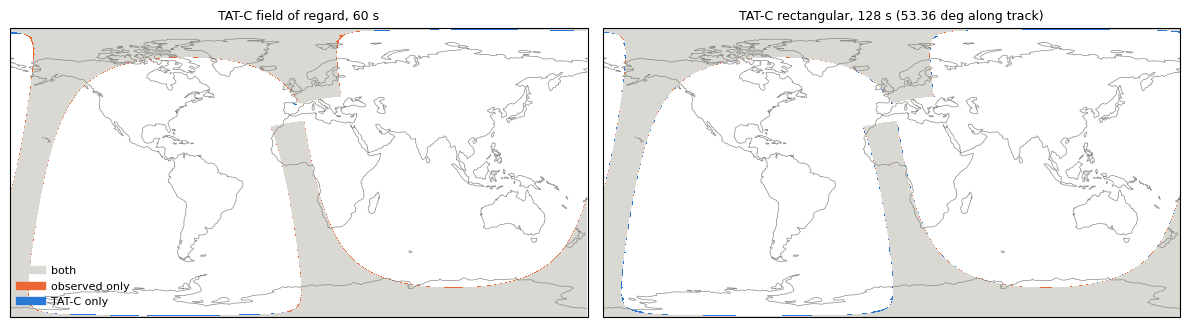

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, name in zip(axes, [list(swath_maps)[0], list(swath_maps)[-1]]):
    predicted = swath_maps[name]
    category = np.where(observed4 & predicted, 1, np.where(observed4, 2, np.where(predicted, 3, 0))).astype(float)
    category[~compared.reshape(lat_grid.shape)] = 0
    ax.pcolormesh(
        lon_grid, lat_grid, np.ma.masked_equal(category, 0),
        cmap=plt.matplotlib.colors.ListedColormap(["#d9d8d3", ORANGE, BLUE]), vmin=0.5, vmax=3.5,
        transform=ccrs.PlateCarree(), shading="auto",
    )
    ax.coastlines(color=GRAY, linewidth=0.5)
    ax.set_global()
    ax.set_title(f"TAT-C {name}", fontsize=9)
axes[0].plot([], [], color="#d9d8d3", lw=6, label="both")
axes[0].plot([], [], color=ORANGE, lw=6, label="observed only")
axes[0].plot([], [], color=BLUE, lw=6, label="TAT-C only")
axes[0].legend(frameon=False, loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

All configurations reproduce the area sampled over one orbit with an intersection over union (IoU) of 0.99. The differences are thin slivers along the swath edges, mostly area observed but not predicted (0.4 to 1.3%), consistent with TAT-C's slightly narrow nominal swath. Tailoring the along-track field of view to the time step makes consecutive rectangular footprints tile the swath at every time step tested, so the time step can be chosen for computational cost. At 128 s, footprints spanning 53 deg along track begin to bulge beyond the swath edges (TAT-C only, 0.9%).

Note that the swath of FOR centers compared here is narrower than the swath of complete footprints: the outermost FORs sample beyond their centers by about half of their cross-track footprint size (Test 5), about 20 km.

## Test 5: Footprint Size

The CrIS geolocation file does not report footprint dimensions. A footprint is the projection of a FOV, a circle 0.963 deg in diameter (a published specification, not derived from the data) onto the surface. Its along-track dimension is the slant range times the angular diameter, and its cross-track dimension is longer by the secant of the satellite zenith angle at the surface (on a flat surface). The reported zenith angles and slant ranges, which describe the viewing geometry, are therefore compared first with TAT-C's: the zenith angle from the satellite's elevation as seen from each pixel (`collect_ground_pixels` with `sat_altaz=True`), and the slant range from the zenith angle and the sub-satellite height on a spherical Earth. The comparison uses the central FOV of each FOR, which the array rotation does not displace.

In [14]:
# TAT-C's satellite zenith angle (from the satellite's elevation as seen from each pixel) at the fitted configuration
track5 = collect_ground_pixels(
    noaa20.model_copy(update={"instruments": [configs["fitted, inertial, tilted"]]}), times3, sat_altaz=True
)
zenith_model = per_for(90 - track5["sat_alt"].to_numpy().reshape(len(i3), N_PIX, 3))[:, :, center]  # (scan, FOR)
zenith_reported = fov_zenith[i3][:, :, center]
range_reported = fov_range[i3][:, :, center]
altitude5 = wgs84.geographic_position_of(orbit.get_orbit_track(times3)).elevation.m  # of the sub-satellite point


def slant_range(altitude, zenith, radius=EARTH_MEAN_RADIUS):
    """Slant range (m) from a satellite to a surface point at a satellite zenith angle (deg), on a spherical Earth."""
    c = radius * np.cos(np.radians(zenith))
    return -c + np.sqrt(c**2 + 2 * radius * altitude + altitude**2)


def footprint_size(range_m, zenith, ifov):
    """Footprint (along-track, cross-track, equivalent-area diameter) in km of a circular field of view (deg)."""
    along = range_m * np.radians(ifov) / 1e3
    cross = along / np.cos(np.radians(zenith))
    return along, cross, np.sqrt(along * cross)


range_model = slant_range(altitude5[:, np.newaxis], zenith_model)
test5 = pd.DataFrame(
    {
        "zenith angle, TAT-C minus reported (deg)": summarize(zenith_model - zenith_reported),
        "slant range, TAT-C minus reported (km)": summarize((range_model - range_reported) / 1e3),
        "equivalent diameter, TAT-C minus reported (km)": summarize(
            footprint_size(range_model, zenith_model, FOV_DIAMETER)[2] - footprint_size(range_reported, zenith_reported, FOV_DIAMETER)[2]
        ),
    }
).T
test5.round(3)

,n,median,p95 |x|,max |x|
"zenith angle, TAT-C minus reported (deg)",1350.0,-0.001,0.006,0.014
"slant range, TAT-C minus reported (km)",1350.0,-0.020,0.276,0.765
"equivalent diameter, TAT-C minus reported (km)",1350.0,-0.000,0.007,0.021


In [15]:
# measured spacing (km) of the views of an array: the mean distance from the central view to its four nearest neighbors
neighbors = [m for m in range(N_FOV) if abs(pixel_cross[m] - 1) + abs(pixel_along[m] - 1) == 1]
view_spacing = np.mean([np.linalg.norm(fov_xyz[:, :, m] - fov_xyz[:, :, center], axis=-1) for m in neighbors], axis=0) / 1e3  # (scan, FOR)
along_r, cross_r, equivalent_r = footprint_size(range_reported, zenith_reported, FOV_DIAMETER)
by_for = lambda a: a.mean(axis=0)  # mean over scans of each field of regard
rows = [0, 4, 9, 14, 15, 19, 24, 29]
table5 = pd.DataFrame(
    {
        "scan angle (deg)": measured[rows],
        "zenith angle (deg)": by_for(zenith_reported)[rows],
        "range (km)": by_for(range_reported)[rows] / 1e3,
        "along-track size (km)": by_for(along_r)[rows],
        "cross-track size (km)": by_for(cross_r)[rows],
        "equivalent diameter (km)": by_for(equivalent_r)[rows],
        "spacing of views (km)": by_for(view_spacing)[rows],
    },
    index=pd.Index(rows, name="field of regard"),
)
table5.round(1)

,scan angle (deg),zenith angle (deg),range (km),along-track size (km),cross-track size (km),equivalent diameter (km),spacing of views (km)
field of regard,,,,,,,
0,48.3,57.6,1385.9,23.3,43.4,31.8,39.6
4,34.9,40.4,1057.7,17.8,23.3,20.4,23.5
9,18.2,20.7,889.3,14.9,16.0,15.5,17.5
14,1.6,1.8,838.9,14.1,14.1,14.1,16.0
15,-1.8,2.0,839.0,14.1,14.1,14.1,16.0
19,-15.1,17.1,872.7,14.7,15.3,15.0,17.0
24,-31.8,36.6,1012.4,17.0,21.2,19.0,21.8
29,-48.4,57.8,1392.7,23.4,44.0,32.1,40.0


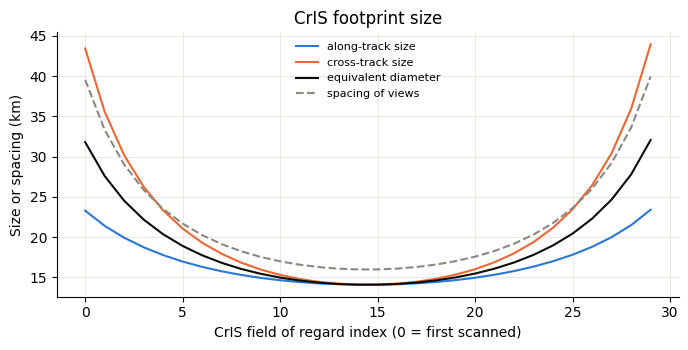

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(N_FOR), by_for(along_r), color=BLUE, label="along-track size")
ax.plot(np.arange(N_FOR), by_for(cross_r), color=ORANGE, label="cross-track size")
ax.plot(np.arange(N_FOR), by_for(equivalent_r), color=INK, label="equivalent diameter")
ax.plot(np.arange(N_FOR), by_for(view_spacing), color=GRAY, ls="--", label="spacing of views")
ax.set(xlabel="CrIS field of regard index (0 = first scanned)", ylabel="Size or spacing (km)", title="CrIS footprint size")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

TAT-C's viewing geometry reproduces the reported zenith angles to 0.006 deg and slant ranges to 0.3 km (95th percentile), so footprint sizes follow to better than 0.01 km. The nadir footprint is 14.1 km, confirming the nominal 14 km. Footprints grow toward the swath edge as the range lengthens (to 1,390 km, compared with 839 km at nadir) and the view slants (to a zenith angle of 58 deg): at the outermost FORs they are 23 km along track and 43 km cross track, an equivalent diameter (that of a circle of the same area) of 32 km, about 2.3 times that at nadir. The views of an array are 16 km apart at nadir and 40 km at the swath edge, so footprints leave gaps (88% fill at nadir, 80% at the edge).

## Summary

The parameters fitted to the NOAA-20 CrIS data, used by the [monsoon OSSE example](../examples/RunOSSEMonsoon.ipynb):

In [17]:
pd.Series(
    {
        "velocity frame": "inertial",
        "FOR spacing (deg)": fitted_spacing,
        "roll angle (deg)": fitted_roll,
        "scan plane tilt, pitch angle (deg)": scan_plane_tilt,
        "FOV pitch (deg)": fov_pitch,
        "FOV diameter, published (deg)": FOV_DIAMETER,
        "field of regard, between outermost FOR centers (deg)": measured.max() - measured.min(),
        "footprint equivalent diameter at nadir (km)": by_for(equivalent_r)[N_FOR // 2 - 1 : N_FOR // 2 + 1].mean(),
        "footprint equivalent diameter at the swath edge (km)": by_for(equivalent_r)[[0, -1]].mean(),
        "center geolocation error, 95th percentile (km)": summarize(
            np.hypot(*[per_for(v)[:, :, center] for v in residuals3["fitted, inertial, tilted, sample times"]])
        ).loc["p95 |x|"],
    }
).round(3)

velocity frame                                           inertial
FOR spacing (deg)                                         3.33399
roll angle (deg)                                        -0.092556
scan plane tilt, pitch angle (deg)                       0.224515
FOV pitch (deg)                                          1.091809
FOV diameter, published (deg)                               0.963
field of regard, between outermost FOR centers (deg)    96.685708
footprint equivalent diameter at nadir (km)              14.10401
footprint equivalent diameter at the swath edge (km)    31.942358
center geolocation error, 95th percentile (km)           0.696837
dtype: object